## Percobaan 1 — Dataset sederhana

Kita mulai dengan enam titik data yang diberi nama a sampai f. Kode berikut menghitung jarak Euclidean antar titik, menampilkan hasilnya sebagai *distance matrix*, lalu membuat dendrogram menggunakan **single linkage**. Dengan contoh kecil ini, proses penggabungan titik yang jaraknya dekat bisa dilihat lebih jelas.

=== Distance Matrix (Euclidean) ===
          a         b         c         d         e         f
a  0.000000  0.707107  5.656854  3.605551  4.242641  3.201562
b  0.707107  0.000000  4.949747  2.915476  3.535534  2.500000
c  5.656854  4.949747  0.000000  2.236068  1.414214  2.500000
d  3.605551  2.915476  2.236068  0.000000  1.000000  0.500000
e  4.242641  3.535534  1.414214  1.000000  0.000000  1.118034
f  3.201562  2.500000  2.500000  0.500000  1.118034  0.000000


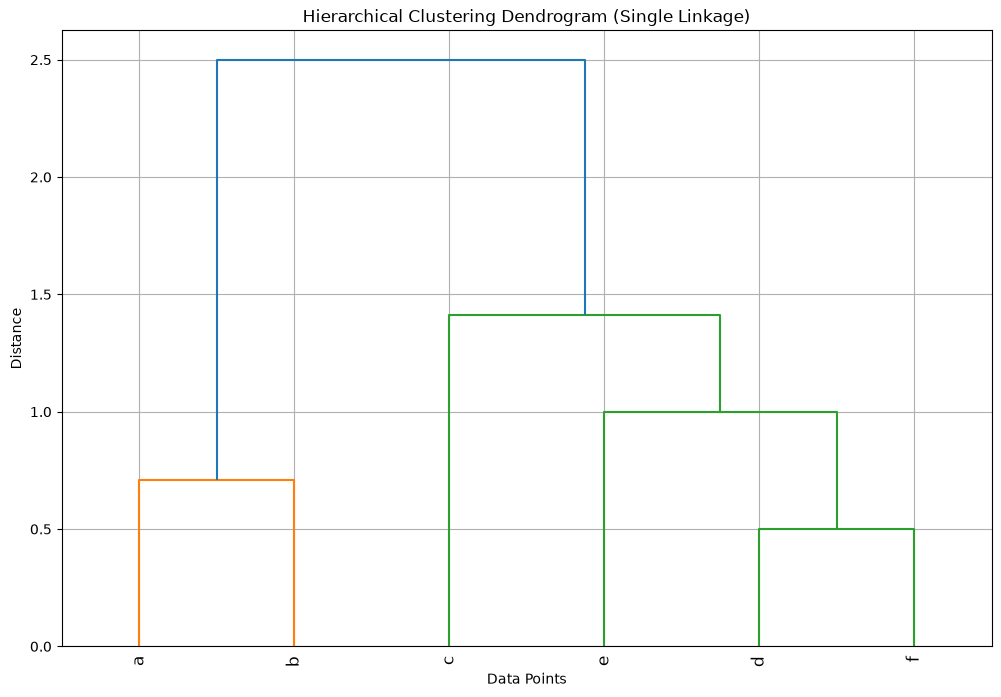

In [1]:
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import pdist, squareform
import matplotlib.pyplot as plt

# 1. Dataset sederhana
data = np.array([
    [1.0, 1.0], # a
    [1.5, 1.5], # b
    [5.0, 5.0], # c
    [3.0, 4.0], # d
    [4.0, 4.0], # e
    [3.0, 3.5]  # f
])

# 2. Hitung Distance Matrix (Euclidean Distance)
distance_matrix = pdist(data, metric='euclidean')
distance_df = pd.DataFrame(
    squareform(distance_matrix),
    columns=['a', 'b', 'c', 'd', 'e', 'f'],
    index=['a', 'b', 'c', 'd', 'e', 'f']
)

# 3. Tampilkan Distance Matrix
print("=== Distance Matrix (Euclidean) ===")
print(distance_df)

# 4. Hierarchical Clustering (Single Linkage)
linked = linkage(data, method='single')

# 5. Plot Dendrogram
plt.figure(figsize=(12, 8))
plt.title("Hierarchical Clustering Dendrogram (Single Linkage)")
dendrogram(linked, labels=['a', 'b', 'c', 'd', 'e', 'f'], leaf_rotation=90)
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.grid(True)
plt.show()

**Cara membaca hasilnya:** tabel *distance matrix* menunjukkan jarak setiap pasangan titik. Nilai diagonalnya nol karena jarak titik ke dirinya sendiri adalah nol. Pada dendrogram, titik yang bergabung pada ketinggian lebih rendah berarti jaraknya lebih dekat menurut metode single linkage.

## Percobaan 2 — Hierarchical Clustering pada Mall Customers

Sekarang kita gunakan dataset Mall Customers. Sesuai modul, fitur yang dipakai adalah **Annual Income** dan **Spending Score**. Kedua fitur distandardisasi lebih dulu supaya perbedaan skala tidak terlalu memengaruhi perhitungan jarak. Setelah itu, kita buat dendrogram dengan metode **complete linkage**.

In [3]:
import pandas as pd
df = pd.read_csv("Mall_Customers.csv")
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Data ditampilkan terlebih dahulu untuk memastikan file berhasil dibaca dan kolom-kolomnya sesuai. Pastikan file `Mall_Customers.csv` ada di folder yang sama dengan notebook ini saat dijalankan di VS Code.

In [4]:
x = df.iloc[:, [3, 4]].values

Baris ini mengambil kolom indeks 3 dan 4, yaitu Annual Income (k$) dan Spending Score (1-100). Hasilnya disimpan sebagai array `x` untuk proses klasterisasi.

In [5]:
from sklearn.preprocessing import StandardScaler

data_scaler = StandardScaler()

scaled_data = data_scaler.fit_transform(x)
scaled_data.shape

(200, 2)

`StandardScaler` menstandarkan nilai kedua fitur agar berada pada skala yang sebanding. Output `(200, 2)` berarti ada 200 pelanggan dan 2 fitur yang digunakan.

In [6]:
from scipy.cluster.hierarchy import linkage, dendrogram

clustering = linkage(scaled_data, method="complete", metric="euclidean")

Fungsi `linkage()` menyusun proses penggabungan klaster. Parameter `method="complete"` menggunakan jarak terjauh antaranggota dua klaster, sedangkan `metric="euclidean"` menentukan cara menghitung jarak.

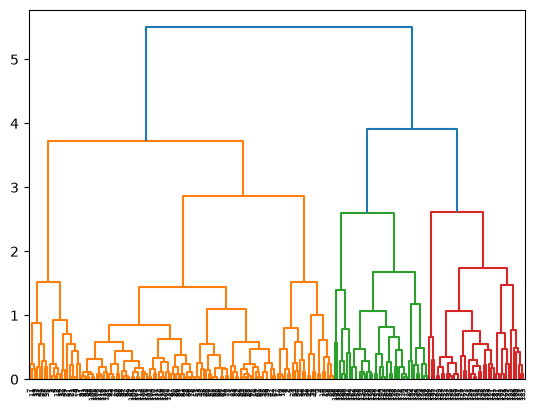

In [7]:
import matplotlib.pyplot as plt

dendrogram(clustering)
plt.show()

Dendrogram memperlihatkan tahapan penggabungan pelanggan. Dengan melihat tinggi penggabungan, kita bisa memperkirakan bagian mana yang cocok dijadikan batas kelompok. Pemilihan jumlah klaster tetap perlu melihat kebutuhan analisis, bukan hanya warna yang muncul pada grafik.

## Tugas — Membandingkan single, complete, dan average linkage

Pada modul, tugasnya adalah membandingkan dendrogram **single linkage** dengan **complete linkage** dan **average linkage** untuk dataset sederhana di percobaan pertama. Kode di bawah memakai enam titik yang sama dan menampilkan ketiga dendrogram berdampingan, supaya perbedaannya lebih mudah dibandingkan.

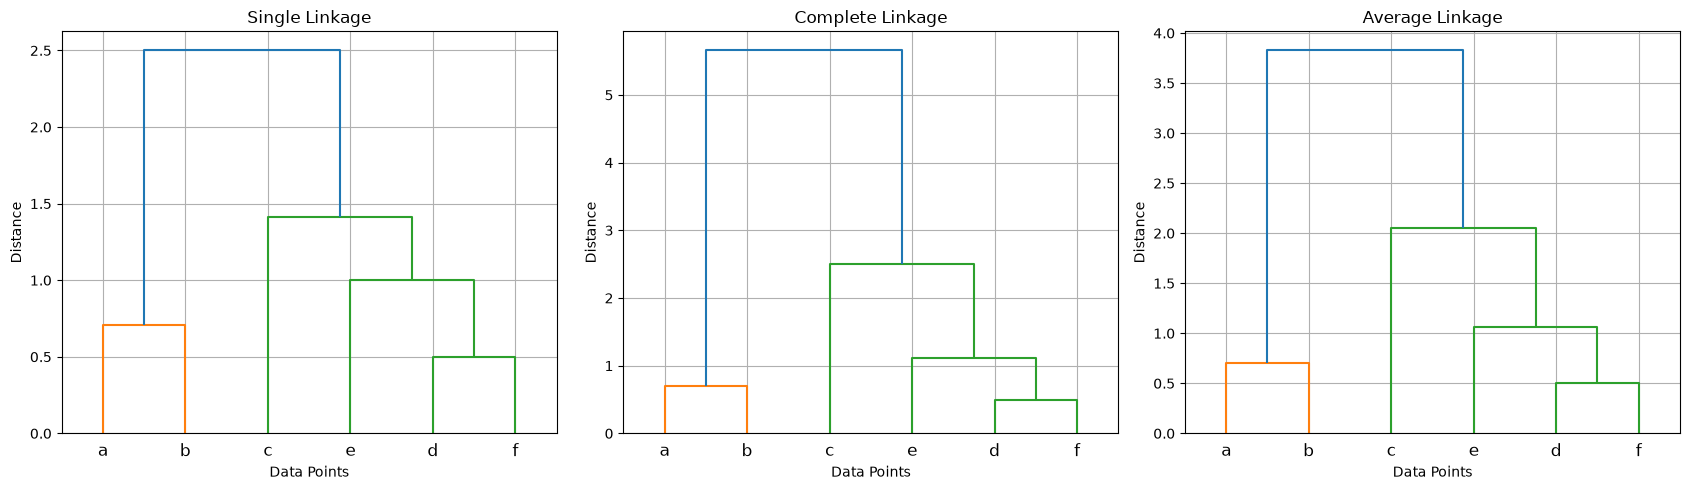

In [8]:
# Bandingkan tiga metode linkage pada dataset sederhana
methods = ['single', 'complete', 'average']
labels = ['a', 'b', 'c', 'd', 'e', 'f']

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, method in zip(axes, methods):
    linked_method = linkage(data, method=method, metric='euclidean')
    dendrogram(linked_method, labels=labels, leaf_rotation=0, ax=ax)
    ax.set_title(f'{method.capitalize()} Linkage')
    ax.set_xlabel('Data Points')
    ax.set_ylabel('Distance')
    ax.grid(True)

plt.tight_layout()
plt.show()

### Perbandingan hasil

- **Single linkage** menggabungkan klaster berdasarkan pasangan titik terdekat. Metode ini bisa membentuk pola berantai ketika ada titik-titik yang saling berdekatan.
- **Complete linkage** memakai pasangan titik terjauh antar dua klaster, sehingga penggabungan lebih mempertimbangkan jarak terjauh di antara anggota klaster.
- **Average linkage** memakai rata-rata jarak antaranggota dari dua klaster yang akan digabungkan.

Karena aturan penggabungannya berbeda, tinggi garis dan urutan penggabungan pada dendrogram bisa berbeda juga. Perhatikan bagian saat kelompok-kelompok besar mulai bergabung untuk melihat perbedaan ketiga metode.